# 06 - Experiments and final results

**Goal of this notebook.** Answer the questions of the assignment that need more than one model:

- Does a **bigger model** help? (hidden size, number of layers)
- Does the **teacher-forcing ratio** matter?
- How much do the results change with the **random seed**?
- What are the **final results on the test set**, with confidence intervals, and which differences between models are real?

**Discipline.** All the choices (which architecture, which size) are made on the **dev set**. The **test set is used once**, at the end, for the final
numbers. The cell that evaluates the test set refuses to run a second time.


Files written by this notebook:

| File | Role |
|---|---|
| `src/t2s/eval/stats.py` | bootstrap confidence intervals |

Tools from earlier notebooks that are used here:

| Tool | What it does | Where it is explained |
|---|---|---|
| `train`, `load_checkpoint` | training and loading a model | notebook 03, section 8 |
| `decode_examples`, `score`, `evaluate_baseline` | generation, exact match and execution accuracy, baseline M0 | notebook 03, sections 1 and 7 |
| `SqliteExecutor`, `load_split` | the database and the data | notebook 01 |

## Setup



In [1]:
import json, os, sys
from pathlib import Path

NOTEBOOK_NUMBER = 6

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/text2sql")
    CODE = "/content/code"                                      # where the notebooks write their code
    DATA_ROOT = "/content/data"                                 # the dataset (downloaded in each session)
    CKPT_DIR = "/content/drive/MyDrive/text2sql_checkpoints"    # the saved models
else:
    PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    CODE, DATA_ROOT, CKPT_DIR = str(PROJECT / "code"), str(PROJECT / "data"), str(PROJECT / "checkpoints")
os.chdir(PROJECT)   # the results are saved in the folder "results" of the project
os.makedirs(CKPT_DIR, exist_ok=True)


def rebuild_code(before):
    """Write again the code files of the notebooks 01 ... before-1 (their writefile cells)."""
    for path in sorted((PROJECT / "notebooks").glob("[0-9][0-9]_*.ipynb")):
        if int(path.name[:2]) >= before:
            continue
        for cell in json.loads(path.read_text())["cells"]:
            source = "".join(cell["source"])
            if cell["cell_type"] != "code" or not source.startswith("%%writefile"):
                continue
            first_line, _, body = source.partition("\n")
            words = first_line.split()
            target = Path(words[-1].replace("{CODE}", CODE))
            target.parent.mkdir(parents=True, exist_ok=True)
            with open(target, "a" if words[1] == "-a" else "w") as f:
                f.write(body if body.endswith("\n") else body + "\n")


for folder in ["src/t2s/data", "src/t2s/models", "src/t2s/decoding", "src/t2s/eval", "scripts", "configs"]:
    os.makedirs(f"{CODE}/{folder}", exist_ok=True)
rebuild_code(NOTEBOOK_NUMBER)
for package in ["src/t2s", "src/t2s/data", "src/t2s/models", "src/t2s/decoding", "src/t2s/eval"]:
    Path(f"{CODE}/{package}/__init__.py").touch()
sys.path.insert(0, f"{CODE}/src")

Mounted at /content/drive


In [2]:
import copy, json
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from t2s.data.download import download_wikisql
from t2s.data.wikisql import load_split, db_path
from t2s.eval.executor import SqliteExecutor
from t2s.train import train, load_checkpoint
from t2s.evaluate import decode_examples
from t2s.eval.metrics import score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

data_dir = download_wikisql(DATA_ROOT)
splits = {name: load_split(data_dir, name) for name in ["train", "dev", "test"]}
dev_executor = SqliteExecutor(db_path(data_dir, "dev"))
Path("results/phase6_experiments").mkdir(parents=True, exist_ok=True)
Path("results/final_test").mkdir(parents=True, exist_ok=True)

device: cpu


## 1. Which architecture is the best?

The size experiments need a model to start from. I take the best of the three models of the previous notebooks (M2 with attention, M3 with copy,
M2 with BPE), **judged on the dev set by exact match**. The rule is fixed here, before looking at the numbers.

In [4]:
dev_scores = {}
for name in ["m2", "m3", "m2_bpe"]:
    path = Path(f"results/{name}/metrics.json")
    if path.exists():
        dev_scores[name] = json.loads(path.read_text())["dev"]["exact_match"]
print("dev exact match:", {name: round(value, 4) for name, value in dev_scores.items()})
assert dev_scores, "No results found: run the notebooks 03, 04 and 05 first (they train the models)."

BEST = max(dev_scores, key=dev_scores.get)
best_config = json.loads(Path(f"results/{BEST}/metrics.json").read_text())["config"]
print("the best architecture on dev:", BEST)

dev exact match: {'m2': 0.4022, 'm3': 0.4934, 'm2_bpe': 0.5485}
the best architecture on dev: m2_bpe


**What I observe.**
 On the dev set, the best model is M2-BPE with 54.9% exact match. M3 follows with 49.3% and M2 has 40.2%.

M2-BPE is 5.5 points above M3 and 14.7 points above M2.
I chose the best architecture on dev, not on test, so the test set stays untouched for the final evaluation.

I use M2-BPE as the starting point for the experiments in the next section.

## 2. The experiments

Each experiment changes **one thing** of the best model's config and trains a new model. The name of a run is the name of the best model plus a
suffix.

Each result is given with the number of parameters, because "bigger" must be measured: the number of parameters is the size of the model.

In [5]:
def variant(suffix, edit):
    config = copy.deepcopy(best_config)
    config["name"] = f"{BEST}_{suffix}"
    edit(config)
    return config

experiments = [
    variant("h128", lambda c: c["model"].update(hidden=128)),
    variant("h512", lambda c: c["model"].update(hidden=512)),
    variant("layers2", lambda c: c["model"].update(num_layers=2)),
    variant("tf05", lambda c: c["train"].update(teacher_forcing=0.5)),
    variant("seed1", lambda c: c.update(seed=1)),
]
for config in experiments:
    print(config["name"])

m2_bpe_h128
m2_bpe_h512
m2_bpe_layers2
m2_bpe_tf05
m2_bpe_seed1


In [6]:
RUN_EXPERIMENTS = []
for config in experiments:
    print("=" * 30, config["name"])
    if config["name"][len(BEST) + 1:] not in RUN_EXPERIMENTS:
        print("skipped")
        continue
    train(config, data_dir, results_dir="results", ckpt_dir=CKPT_DIR, resume=True)

============================== m2_bpe_h128
skipped
============================== m2_bpe_h512
skipped
============================== m2_bpe_layers2
skipped
============================== m2_bpe_tf05
skipped
============================== m2_bpe_seed1
skipped


## 3. Does a bigger model help?

All the runs are compared on the **dev set**, with the number of parameters.

In [7]:
def dev_row(name, label):
    path = Path(f"results/{name}/metrics.json")
    if not path.exists():
        return None
    result = json.loads(path.read_text())
    dev = result["dev"]
    return {"run": label, "parameters": result["parameters"], "best epoch": result["best_epoch"],
            "exact match": round(dev["exact_match"], 4), "execution accuracy": round(dev["execution_accuracy"], 4),
            "dev loss": round(dev["loss"], 3)}

runs = [(BEST, f"{BEST} (hidden 256, 1 layer)"), (f"{BEST}_h128", "hidden 128"), (f"{BEST}_h512", "hidden 512"),
        (f"{BEST}_layers2", "2 layers"), (f"{BEST}_tf05", "teacher forcing 0.5"), (f"{BEST}_seed1", "seed 1")]
rows = [row for row in (dev_row(name, label) for name, label in runs) if row]
experiment_table = pd.DataFrame(rows).set_index("run")
experiment_table.to_csv("results/phase6_experiments/experiments.csv")
experiment_table.assign(parameters=experiment_table["parameters"].map("{:,}".format))

,parameters,best epoch,exact match,execution accuracy,dev loss
run,,,,,
"m2_bpe (hidden 256, 1 layer)","6,830,168",8,0.5485,0.6114,0.318
hidden 128,"4,587,480",8,0.4103,0.4838,0.427
seed 1,"6,830,168",8,0.5539,0.6141,0.303


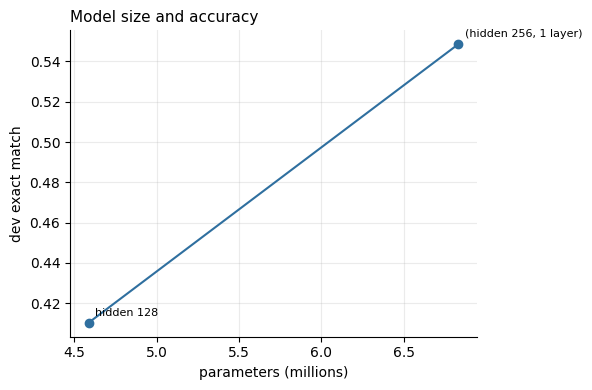

In [8]:
size_runs = experiment_table.loc[[r for r in experiment_table.index if r in
                                  (f"{BEST} (hidden 256, 1 layer)", "hidden 128", "hidden 512", "2 layers")]].sort_values("parameters")
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(size_runs["parameters"] / 1e6, size_runs["exact match"], "o-", color="#2f6f9f")
for run, row in size_runs.iterrows():
    ax.annotate(run.replace(f"{BEST} ", ""), (row["parameters"] / 1e6, row["exact match"]), textcoords="offset points", xytext=(5, 5), fontsize=8)
ax.set_xlabel("parameters (millions)")
ax.set_ylabel("dev exact match")
ax.set_title("Model size and accuracy", loc="left", fontsize=11)
ax.grid(alpha=0.25)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.savefig("results/phase6_experiments/size_vs_accuracy.png", dpi=150)
plt.show()

**What I observe.**
A smaller model is clearly worse. With hidden size 128 (4.6 million parameters), exact match is 41.0% and execution accuracy is 48.4%. With hidden size 256 (6.8 million), they are 54.9% and 61.1%. Cutting the size by one third costs about 14 points. The dev loss also goes from 0.318 to 0.427.

The size experiment has only two points, so I cannot say where the gain stops. I did not train hidden 512 or two layers, because of the compute limit. I only know that going from 128 to 256 helps a lot.

Both runs trained for the same 8 epochs, and both still improved at the last epoch. The smaller model might close part of the gap with more epochs, so the gap is partly a question of speed of learning.

The seed changes the result very little. The same model with another seed gets 55.4% exact match against 54.9% (a difference of 0.5 points), and a dev loss of 0.303 against 0.318. So the differences between the main models (6 to 15 points) are much larger than the noise from training. This is one extra seed, so I do not give an exact interval.

Answer to the complexity question: in my runs, more capacity helped up to hidden size 256 for the same budget, but I did not test larger sizes, so I do not claim that bigger is always better.

## 4. Confidence intervals

A score measured on N test questions is an estimate. The **bootstrap** draws N questions *with replacement*, many times, and gives the range of the
scores: the 95% confidence interval. To compare two models on the same questions, I use a **paired bootstrap** of the difference of their scores.

**The description** in the docstring explains the bootstrap and the paired bootstrap.

In [8]:
%%writefile {CODE}/src/t2s/eval/stats.py
"""Confidence intervals by bootstrap.

A score measured on a test set of N questions is only an estimate: with another set of N
questions it would be a little different. The bootstrap measures this. It draws, many times,
N questions *with replacement* from the test set, computes the score of each draw, and takes
the middle 95% of these scores as the confidence interval.

To compare two models on the same questions, the draw is the same for both and the difference
of their scores is computed (paired bootstrap): if the interval of the difference does not
contain 0, the difference is unlikely to be due to the choice of questions.
"""

import numpy as np




Writing /content/code/src/t2s/eval/stats.py


**`_resample_means`** draws `n_resamples` samples (of the size of the data, with replacement) and returns the mean of each. It works by chunks of 100
samples, to limit the memory.

In [9]:
%%writefile -a {CODE}/src/t2s/eval/stats.py
def _resample_means(values: np.ndarray, n_resamples: int, seed: int) -> np.ndarray:
    rng = np.random.default_rng(seed)
    means = np.empty(n_resamples)
    chunk = 100  # a few resamples at a time, to limit the memory
    for start in range(0, n_resamples, chunk):
        size = min(chunk, n_resamples - start)
        draws = rng.integers(0, len(values), size=(size, len(values)))
        means[start : start + size] = values[draws].mean(axis=1)
    return means




Appending to /content/code/src/t2s/eval/stats.py


**`bootstrap_mean`** gives the mean of the values and the 95% interval: the 2.5th and the 97.5th percentile of the resampled means.

In [10]:
%%writefile -a {CODE}/src/t2s/eval/stats.py
def bootstrap_mean(values, n_resamples: int = 1000, seed: int = 0, level: float = 0.95) -> tuple[float, float, float]:
    """The mean of `values` and its confidence interval: (mean, low, high)."""
    values = np.asarray(values, dtype=float)
    means = _resample_means(values, n_resamples, seed)
    low, high = np.percentile(means, [(1 - level) / 2 * 100, (1 + level) / 2 * 100])
    return float(values.mean()), float(low), float(high)




Appending to /content/code/src/t2s/eval/stats.py


**`paired_bootstrap_difference`** does the same for the difference of two series of scores of the same questions.

In [11]:
%%writefile -a {CODE}/src/t2s/eval/stats.py
def paired_bootstrap_difference(a, b, n_resamples: int = 1000, seed: int = 0, level: float = 0.95) -> tuple[float, float, float]:
    """The mean of a - b (the two models scored on the same questions) and its confidence interval."""
    difference = np.asarray(a, dtype=float) - np.asarray(b, dtype=float)
    return bootstrap_mean(difference, n_resamples, seed, level)


Appending to /content/code/src/t2s/eval/stats.py


## 5. The final evaluation on the test set

This is the only place where the test set is used. For each model of the ladder, the best checkpoint (chosen on dev) is loaded, the 15,878 test questions
are decoded (greedy decoding), and each query is scored. The per-question results are saved, so the evaluation is never repeated: if the file exists, it
is read instead.

In [12]:
FLAGS_PATH = Path("results/final_test/test_flags.json")
test, test_executor = splits["test"], SqliteExecutor(db_path(data_dir, "test"))
final_models = ["m0", "m1", "m1b", "m2", "m3", "m2_bpe"]

if FLAGS_PATH.exists():
    flags = json.loads(FLAGS_PATH.read_text())
    print("The test set was already evaluated. The saved results are used; the test set is not used again.")
else:
    from t2s.eval.baseline import baseline_outputs
    flags = {}
    for name in final_models:
        if name == "m0":
            outputs = baseline_outputs(splits["train"], test)
        else:
            path = Path(CKPT_DIR) / name / "best.pt"
            if not path.exists():
                continue
            model, codec, cfg = load_checkpoint(path, device)
            outputs = decode_examples(model, test, codec, device, cfg["data"]["max_src_len"], cfg["data"]["max_tgt_len"])
        _, predictions = score(test, outputs, test_executor)
        flags[name] = {"exact": [int(p.exact) for p in predictions], "correct": [int(p.correct) for p in predictions],
                       "valid": [int(p.query is not None) for p in predictions]}
        print(f"{name:8s} exact match {np.mean(flags[name]['exact']):.4f}   execution accuracy {np.mean(flags[name]['correct']):.4f}")
    FLAGS_PATH.write_text(json.dumps(flags))

m0       exact match 0.0000   execution accuracy 0.0000
m1       exact match 0.1687   execution accuracy 0.2143
m1b      exact match 0.1588   execution accuracy 0.2027
m2       exact match 0.3975   execution accuracy 0.4439
m3       exact match 0.4824   execution accuracy 0.5594
m2_bpe   exact match 0.5462   execution accuracy 0.6052


In [13]:
from t2s.eval.stats import bootstrap_mean, paired_bootstrap_difference

params = {name: json.loads(Path(f"results/{name}/metrics.json").read_text())["parameters"] for name in flags if Path(f"results/{name}/metrics.json").exists()}
rows = []
for name, f in flags.items():
    exact, low_e, high_e = bootstrap_mean(f["exact"])
    correct, low_c, high_c = bootstrap_mean(f["correct"])
    rows.append({"model": name, "parameters": f"{params.get(name, 0):,}",
                 "exact match": f"{exact:.3f} [{low_e:.3f}, {high_e:.3f}]",
                 "execution accuracy": f"{correct:.3f} [{low_c:.3f}, {high_c:.3f}]",
                 "valid format": f"{np.mean(f['valid']):.3f}"})
final_table = pd.DataFrame(rows).set_index("model")
final_table.to_csv("results/final_test/test_results.csv")
final_table

,parameters,exact match,execution accuracy,valid format
model,,,,
m0,0,"0.000 [0.000, 0.000]","0.000 [0.000, 0.000]",1.000
m1,"13,326,426","0.169 [0.163, 0.175]","0.214 [0.208, 0.220]",0.721
m1b,"14,115,418","0.159 [0.153, 0.165]","0.203 [0.196, 0.209]",0.698
m2,"14,509,402","0.398 [0.390, 0.405]","0.444 [0.436, 0.451]",0.871
m3,"14,510,427","0.482 [0.474, 0.490]","0.559 [0.552, 0.567]",0.921
m2_bpe,"6,830,168","0.546 [0.538, 0.554]","0.605 [0.598, 0.612]",0.862


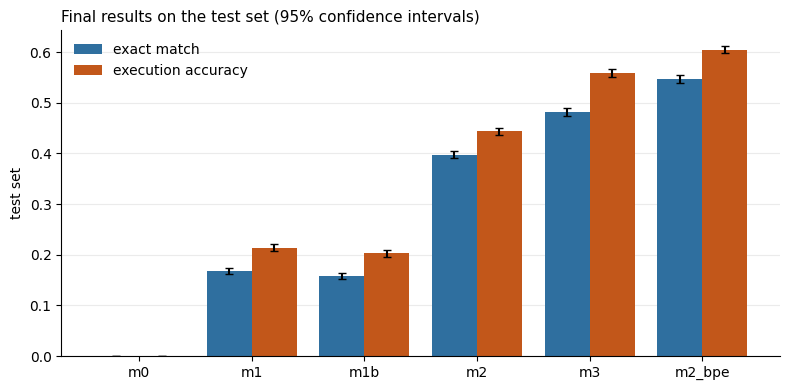

In [14]:
names = list(flags)
exact = [np.mean(flags[n]["exact"]) for n in names]
correct = [np.mean(flags[n]["correct"]) for n in names]
err_e = [[e - bootstrap_mean(flags[n]["exact"])[1] for n, e in zip(names, exact)], [bootstrap_mean(flags[n]["exact"])[2] - e for n, e in zip(names, exact)]]
err_c = [[c - bootstrap_mean(flags[n]["correct"])[1] for n, c in zip(names, correct)], [bootstrap_mean(flags[n]["correct"])[2] - c for n, c in zip(names, correct)]]

x = np.arange(len(names))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - 0.2, exact, 0.4, yerr=err_e, color="#2f6f9f", label="exact match", capsize=3)
ax.bar(x + 0.2, correct, 0.4, yerr=err_c, color="#c2571a", label="execution accuracy", capsize=3)
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylabel("test set")
ax.set_title("Final results on the test set (95% confidence intervals)", loc="left", fontsize=11)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.savefig("results/final_test/test_results.png", dpi=150)
plt.show()

**What I observe.**

The intervals are narrow (about ±0.6 to ±0.8 points), because the test set has 15,878 questions. The scores are therefore precise estimates.
M2, M3 and M2-BPE are clearly separated. Their intervals don’t overlap, so each model is really better than the one before it, at least for these trained models.

M1 and M1b are close, and their intervals nearly touch. I don’t conclude anything about them from this chart. The paired test in section 6 is the right way to compare them.

The confidence interval only measures the noise of the test questions. It does not measure the noise from training (a different seed). I look at that separately with the seed experiment.

Execution accuracy is above exact match for every model. The gap is about 4 to 8 points, and it is largest for M3 (7.7 points).

## 6. Which differences are real?

The paired bootstrap of the difference between two models on the same test questions. If the interval does not contain 0, the difference is unlikely to be
due to the choice of the questions.

In [15]:
comparisons = [("m1", "m1b", "reading in both directions"), ("m1b", "m2", "attention"), ("m2", "m3", "copy mechanism"),
               ("m2", "m2_bpe", "BPE instead of words"), ("m0", "m1", "learning at all")]
rows = []
for base, better, what in comparisons:
    if better in flags and base in flags:
        for metric in ("exact", "correct"):
            diff, low, high = paired_bootstrap_difference(flags[better][metric], flags[base][metric])   # improved minus base
            rows.append({"change": f"{base} -> {better}: {what}", "metric": "exact match" if metric == "exact" else "execution accuracy",
                         "difference": f"{diff:+.3f}", "95% interval": f"[{low:+.3f}, {high:+.3f}]",
                         "real?": "yes" if low > 0 or high < 0 else "not shown"})
pd.DataFrame(rows)

,change,metric,difference,95% interval,real?
0,m1 -> m1b: reading in both directions,exact match,-0.010,"[-0.014, -0.006]",yes
1,m1 -> m1b: reading in both directions,execution accuracy,-0.012,"[-0.016, -0.007]",yes
2,m1b -> m2: attention,exact match,+0.239,"[+0.232, +0.245]",yes
3,m1b -> m2: attention,execution accuracy,+0.241,"[+0.234, +0.248]",yes
4,m2 -> m3: copy mechanism,exact match,+0.085,"[+0.076, +0.093]",yes
5,m2 -> m3: copy mechanism,execution accuracy,+0.115,"[+0.107, +0.124]",yes
6,m2 -> m2_bpe: BPE instead of words,exact match,+0.149,"[+0.142, +0.157]",yes
7,m2 -> m2_bpe: BPE instead of words,execution accuracy,+0.161,"[+0.154, +0.170]",yes
8,m0 -> m1: learning at all,exact match,+0.169,"[+0.163, +0.175]",yes
9,m0 -> m1: learning at all,execution accuracy,+0.214,"[+0.208, +0.220]",yes


In [16]:
diff_e, low_e, high_e = paired_bootstrap_difference(flags["m2_bpe"]["exact"], flags["m3"]["exact"])
diff_c, low_c, high_c = paired_bootstrap_difference(flags["m2_bpe"]["correct"], flags["m3"]["correct"])
print(f"m3 -> m2_bpe, exact match:        {diff_e:+.3f}  [{low_e:+.3f}, {high_e:+.3f}]")
print(f"m3 -> m2_bpe, execution accuracy: {diff_c:+.3f}  [{low_c:+.3f}, {high_c:+.3f}]")

m3 -> m2_bpe, exact match:        +0.064  [+0.056, +0.072]
m3 -> m2_bpe, execution accuracy: +0.046  [+0.038, +0.054]


**What I observe.**

M2-BPE is better than M3, and the difference is real. On the test set, M2-BPE is +6.4 points higher in exact match (95% interval [+5.6, +7.2]) and +4.6 points higher in execution accuracy (interval [+3.8, +5.4]). Neither interval contains 0.

M2-BPE is the best model of the project. It is also the smallest of the three best models (6.8 million parameters, against 14.5 million for M2 and M3).

M2-BPE has fewer training epochs than M3 (8 against 10), so the budget does not explain its advantage. The difference is a gap between two single training runs. The seed experiment shows how much a run changes with another seed.

## 7. Summary of this notebook

**What I did:** trained variants of the best model (smaller, bigger, deeper, another teacher-forcing ratio, another seed), measured the final results on
the test set once, and added confidence intervals and paired comparisons.

**Next notebook:** `07_error_analysis.ipynb` looks at the mistakes of the best model.